# mHypothalamus Data

In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import anndata
import os
import random
from sklearn.metrics import adjusted_rand_score

import scSLAT
from scSLAT.model import Cal_Spatial_Net, load_anndatas, run_SLAT, spatial_match
from scSLAT.viz import match_3D_multi, hist, Sankey

import warnings
warnings.filterwarnings("ignore")

## Load Data

In [2]:
def load_mHy(info_file, cnts_file, section_id):

    # section id = '0.26', '0.21', '0.16', '0.11', '0.06', '0.01', '-0.04', '-0.09', '-0.14', '-0.19', '-0.24', '-0.29' 12 in total
    # cluster =     15      15      14      15      15      15      14       15       15       15      16        15
    # 9 clusters: ['BST' 'MPA' 'MPN' 'PV' 'PVH' 'PVT' 'V3' 'fx'] n_obs × n_vars = 5488 × 155
    xls_cnts = pd.ExcelFile(cnts_file)
    # print(xls_cnts.sheet_names)

    df_cnts = pd.read_excel(xls_cnts, section_id)
    xls_info = pd.ExcelFile(info_file)
    df_info = pd.read_excel(xls_info, section_id)
    # print(df_cnts, df_info)
    spatial_X = df_info.to_numpy()
    obs_ = df_info
    if len(df_info.columns) == 5:
        obs_.columns = ['psuedo_barcodes', 'x', 'y', 'original_clusters', 'Neuron_cluster_ID']
    elif len(df_info.columns) == 6:
        obs_.columns = ['psuedo_barcodes', 'x', 'y', 'cell_types', 'Neuron_cluster_ID', 'original_clusters']
    obs_.index = obs_['psuedo_barcodes'].tolist()
    # print(obs_)

    var_ = df_cnts.iloc[:, 0]
    var_ = pd.DataFrame(var_)
    # print(var_)

    ad = anndata.AnnData(X=df_cnts.iloc[:,1:].T, obs=obs_, var=var_)
    spatial = np.vstack((ad.obs['x'].to_numpy(), ad.obs['y'].to_numpy()))
    ad.obsm['spatial'] = spatial.T
    return ad

In [3]:
info_file = '/pkl_data/MERFISH_Animal1_info.xlsx'
cnts_file = '/pkl_data/MERFISH_Animal1_cnts.xlsx'

section_id = '-0.14' #, '-0.09', '-0.14', '-0.19', '-0.24'
ad_target = load_mHy(info_file, cnts_file, section_id)

section_id = '-0.09'
ad = load_mHy(info_file, cnts_file, section_id)

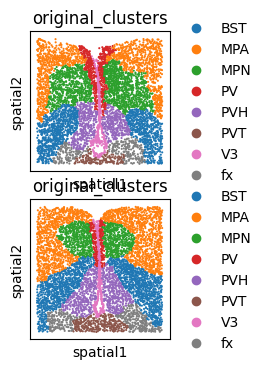

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(6, 4))
sc.pl.spatial(ad, color='original_clusters', spot_size=30, ax=axes[0], show=False)
sc.pl.spatial(ad_target, color='original_clusters', spot_size=30, ax=axes[1], show=False)
plt.show()

In [5]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)  # If using multi-GPU
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False  # May slow down training


def cal_laa_ari(ad_df):
    true_clusters_mapped_region = []  # Define lists inside the function
    mapped_clusters_mapped_region = []
    cnt = 0  
    
    for i in range(len(ad_df)):
        f1_cluster = ad_df.iloc[i]['target_celltype']
        f2_cluster = ad_df.iloc[i]['celltype']
        true_clusters_mapped_region.append(f1_cluster)
        mapped_clusters_mapped_region.append(f2_cluster)
        if f1_cluster == f2_cluster:
            cnt += 1 

    laa = cnt/len(ad_df)
    ari = adjusted_rand_score(true_clusters_mapped_region, mapped_clusters_mapped_region)
              
    return laa,ari

In [6]:
seeds_to_run = [2024, 1, 2, 3, 4, 10, 11, 12, 13, 14]

# seeds_to_run = [2024, 1]

for seed in seeds_to_run:
    print('--------------'+ str(seed))
    set_seed(seed)
    
    # Calculating spatial neighbor graph
    Cal_Spatial_Net(ad_target, k_cutoff=10, model='KNN')
    Cal_Spatial_Net(ad, k_cutoff=10, model='KNN')
    
    # Use DPCA feature to format graph
    edges, features = load_anndatas([ad_target, ad], feature='PCA', check_order=False)
    embd0, embd1, time = run_SLAT(features, edges)
    best, index, distance = spatial_match([embd0, embd1], adatas=[ad_target, ad], reorder=False)
    
    ad_target_df = pd.DataFrame({'index': range(embd0.shape[0]),
                            'x': ad_target.obsm['spatial'][:,0],
                            'y': ad_target.obsm['spatial'][:,1],
                            'celltype': ad_target.obs['original_clusters']})
    ad_df = pd.DataFrame({'index': range(embd1.shape[0]),
                            'x': ad.obsm['spatial'][:,0],
                            'y': ad.obsm['spatial'][:,1],
                            'celltype': ad.obs['original_clusters']})

    matching = np.array([range(index.shape[0]), best])
    best_match = distance[:,0]

    ad_df['target_index'] = best
    ad_df['target_celltype'] = ad_target_df.iloc[matching[1,:],:]['celltype'].to_list()
    ad_df['cos_similarity'] = best_match
    
    ad_df.to_csv(f'/pkl_data/{seed}/mHypothalamus_-0.09.csv', index=False)
    
    laa,ari = cal_laa_ari(ad_df)
    print(f'LAA: {laa}')
    print(f'ARI: {ari}')
    
    column = '-0.09_-0.14'
    filename = 'mHypothalamus_ARI.csv'
    excel_path = f'/pkl_data/{seed}/{filename}'
    header = [' ', '-0.09_-0.14']

    # Check if the file exists
    if not os.path.exists(excel_path):
        # Define the header and first row
        first_row = [[0, ari]]
        # Create a DataFrame
        df = pd.DataFrame(first_row, columns=header)
        print(df)
        # Save as a CSV file
        df.to_csv(excel_path, index=False)
        
    filename = 'mHypothalamus_LAA.csv'
    excel_path = f'/pkl_data/{seed}/{filename}'
    # Check if the file exists
    if not os.path.exists(excel_path):
        # Define the header and first row
        first_row = [[0, laa]]
        # Create a DataFrame
        df = pd.DataFrame(first_row, columns=header)
        print(df)
        # Save as a CSV file
        df.to_csv(excel_path, index=False)
        
    filename = 'mHypothalamus_RunTime.xlsx'
    excel_path = f'/pkl_data/{seed}/{filename}'
    # Check if the file exists
    if not os.path.exists(excel_path):
        # Define the header and first row
        first_row = [[0, time]]
        # Create a DataFrame
        df = pd.DataFrame(first_row, columns=header)
        print(df)
        # Save as a CSV file
        df.to_excel(excel_path, index=False)

--------------2024
Calculating spatial neighbor graph ...
The graph contains 65926 edges, 5926 cells.
11.12487343908201 neighbors per cell on average.
Calculating spatial neighbor graph ...
The graph contains 62139 edges, 5557 cells.
11.182112650710815 neighbors per cell on average.
Use PCA feature to format graph
All genes are highly variable.
Choose GPU:0 as device
Running
Training model time: 1.38
LAA: 0.7201727550836783
ARI: 0.4693993204869318
      -0.09_-0.14
0  0     0.469399
      -0.09_-0.14
0  0     0.720173
      -0.09_-0.14
0  0     1.378931
--------------1
Calculating spatial neighbor graph ...
The graph contains 65926 edges, 5926 cells.
11.12487343908201 neighbors per cell on average.
Calculating spatial neighbor graph ...
The graph contains 62139 edges, 5557 cells.
11.182112650710815 neighbors per cell on average.
Use PCA feature to format graph
All genes are highly variable.
Choose GPU:0 as device
Running
Training model time: 1.11
LAA: 0.7275508367824366
ARI: 0.47993102

In [ ]:
seeds_to_run = [2024, 1, 2, 3, 4, 10, 11, 12, 13, 14]

# seeds_to_run = [2024, 1]

for seed in seeds_to_run:
    print('--------------'+ str(seed))
    set_seed(seed)
    
    # Calculating spatial neighbor graph
    Cal_Spatial_Net(ad_target, k_cutoff=10, model='KNN')
    Cal_Spatial_Net(ad, k_cutoff=10, model='KNN')
    
    # Use DPCA feature to format graph
    edges, features = load_anndatas([ad_target, ad], feature='PCA', check_order=False)
    embd0, embd1, time = run_SLAT(features, edges)
    best, index, distance = spatial_match([embd0, embd1], adatas=[ad_target, ad], reorder=False)
    
    ad_target_df = pd.DataFrame({'index': range(embd0.shape[0]),
                            'x': ad_target.obsm['spatial'][:,0],
                            'y': ad_target.obsm['spatial'][:,1],
                            'celltype': ad_target.obs['original_clusters']})
    ad_df = pd.DataFrame({'index': range(embd1.shape[0]),
                            'x': ad.obsm['spatial'][:,0],
                            'y': ad.obsm['spatial'][:,1],
                            'celltype': ad.obs['original_clusters']})

    matching = np.array([range(index.shape[0]), best])
    best_match = distance[:,0]

    ad_df['target_index'] = best
    ad_df['target_celltype'] = ad_target_df.iloc[matching[1,:],:]['celltype'].to_list()
    ad_df['cos_similarity'] = best_match
    
    ad_df.to_csv(f'/pkl_data/{seed}/mHypothalamus_-0.14.csv', index=False)
    
    laa,ari = cal_laa_ari(ad_df)
    print(f'LAA: {laa}')
    print(f'ARI: {ari}')
    
    column = '-0.14_-0.19'
    filename = 'mHypothalamus_ARI.csv'
    excel_path = f'/pkl_data/{seed}/{filename}'
    # Load existing file
    df = pd.read_csv(excel_path)
    df.at[0, column] = ari
    print(df)
    # Save as a CSV file
    df.to_csv(excel_path, index=False)
        
    filename = 'mHypothalamus_LAA.csv'
    excel_path = f'/pkl_data/{seed}/{filename}'
    # Load existing file
    df = pd.read_csv(excel_path)
    df.at[0, column] = laa
    print(df)
    # Save as a CSV file
    df.to_csv(excel_path, index=False)
        
    filename = 'mHypothalamus_RunTime.xlsx'
    excel_path = f'/pkl_data/{seed}/{filename}'
    # Load existing file
    df = pd.read_excel(excel_path)
    df.at[0, column] = time
    print(df)
    # Save as a CSV file
    df.to_excel(excel_path, index=False)